# Calibration modification test

The goal of this investigation is to see the impact of calibration error on individualimage projections. 
For example, how does a pitch angle estimation effect the projection along/across track
Or, are these more lens distortion errors?

In [2]:
from groundNAV_agent import gNAV_agent
# from microp_distb import microp_distb
# from distb_plt_utils import microp_distb_plotter

import pycolmap

import numpy as np
import open3d as o3d
import copy
import pickle
import cv2
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree

# SAVE YOUR WORK
%load_ext autoreload
%autoreload 2
%autosave 180

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


Autosaving every 180 seconds


In [3]:
# Upload dataset inputs

# Colmap data
colm_fn = "../datasets/KBCB_colm/"

# Local test images 
im_local = '../datasets/KBCB_test_images/' # With 10 local images 
# New local test image - frame 28599 NOT in COLMAP 
# im_local = '../datasets/LSA_test_images/'

# Satellite ref 
sat_ref = "../datasets/KBCB_satellite/KBCB_partial.jpg" # Public google earth satellite imagery
# sat_ref = "../datasets/KBCB_satellite/KBCB_partial_LSA.png" # Public google earth satellite imagery

# Ground truth solutions
ind_params_KBCB = np.load("ind_params_KBCB_FULL.npy")

In [4]:
# Create class 
gnav = gNAV_agent(colm_fn, im_local, sat_ref, ind_params_KBCB)

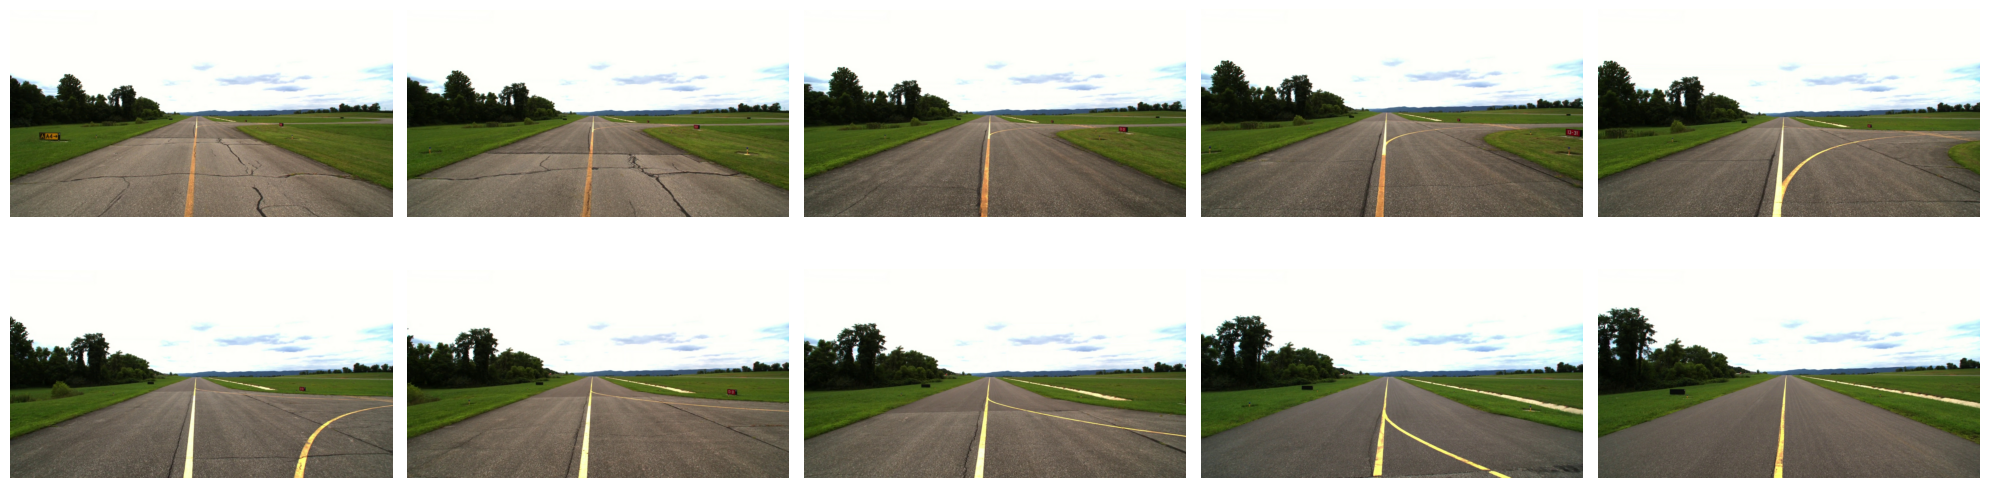

In [5]:
# Visualizer 
gnav.visualize_local_ims()

In [6]:
# Using pre_calculated ground plane points - read explanation below 
pts_gnd_idx = np.load('../datasets/KBCB_params/ground_pts_idxs.npy')
gnav.pts_gnd_idx = pts_gnd_idx
# Run the ground plane extractor for visualization purposes 
pts_gnd_idx_test = gnav.get_gnd_pts() 
# # Visualize ground plane points 
# gnav.visualize_ground_pts(pts_gnd_idx_test) # UNCOMMENT for visualizations 

In [7]:
# Gather reference frame
tform_ref_frame = gnav.set_ref_frame() 
tform_ref_frame_pts = gnav.inv_homog_transform(tform_ref_frame)
gnav.tform_ref_frame_pts = tform_ref_frame_pts
print("\nReference frame transformation\n", tform_ref_frame_pts)

# Transform all points to the new coordinate system - for visual check 
tform_ref_frame_inv = gnav.inv_homog_transform(tform_ref_frame)
origin_ref, scene_pts_ref, scene_vec_ref = gnav.unit_vec_tform(gnav.scene_pts, gnav.origin_w, tform_ref_frame_inv)
gnav.scene_pts_ref = scene_pts_ref

Gravity vector 
 [-0.00516537  0.99923869  0.03866977]

Height h_0 =  0.09328363092429819

Reference frame transformation
 [[ 0.61692741  0.03361836 -0.7863017   0.20779018]
 [-0.7870031   0.01979491 -0.6166314  -0.15853791]
 [-0.00516537  0.99923869  0.03866977  0.90871723]
 [ 0.          0.          0.          1.        ]]


In [8]:
# Visualizer
gnav.visualize_ref_frame(scene_pts_ref)
# Optionally, view the direction of the gravity vector
# gnav.visualize_grav_vec()

867 1600 ytot xtot


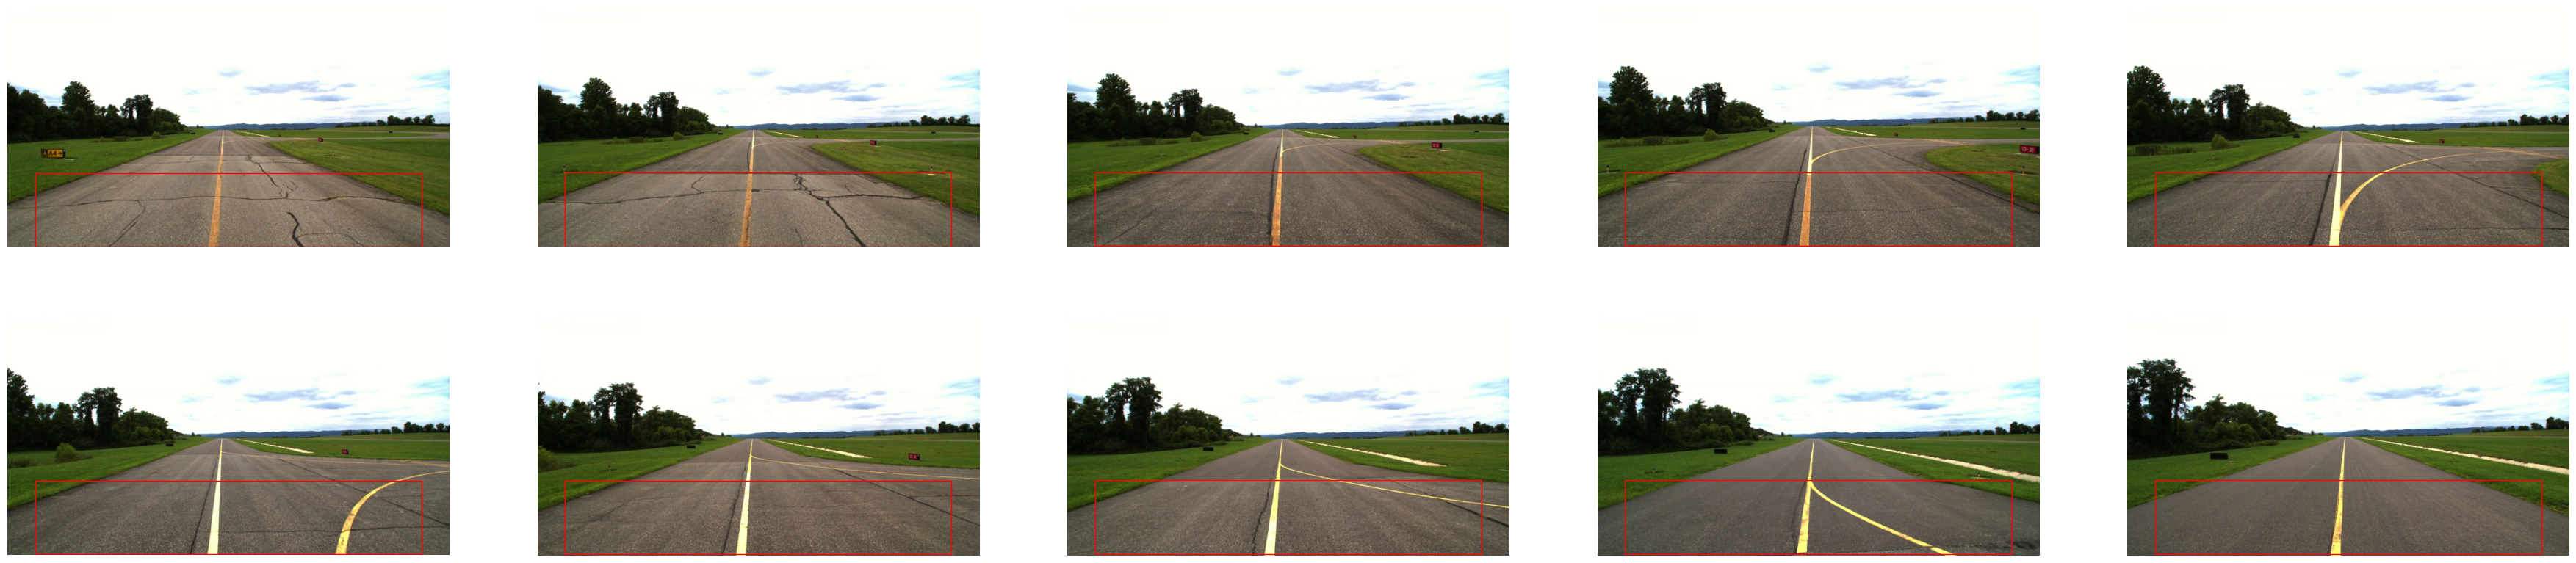

In [9]:
%matplotlib qt
# Prune points and create mask
# pts = gnav.prune_satellite_image()

# AUTOMATED PATCH EXTRACTION 
%matplotlib inline
# Initial size
params_tot = gnav.get_initial_params()
# Grab points and plot
gnav.grab_image_pts_tot(params_tot)
gnav.plot_gnd_pts()

In [10]:
# ROI PROJECTION FUNCTION 

def project_roi(gnav, rois, d_pitch=0.0):
    """
    Grab ROI pixels and project onto the ground plane in the ref frame 
    Input: rois (num_ims x 4), each row (x, y, width, height)
           d_pitch: pitch perturbation (deg) about camera x-axis, applied to ALL images
                    + = optical axis tips up (COLMAP cam: y down, z forward)
    """
    gnav.grab_image_pts_tot(np.asarray(rois))

    # Pitch perturbation in camera frame (rotation about cam x, no translation)
    c, s = np.cos(np.deg2rad(d_pitch)), np.sin(np.deg2rad(d_pitch))
    T_pitch = np.array([[1, 0, 0, 0],
                        [0, c, -s, 0],
                        [0, s, c, 0],
                        [0, 0, 0, 1]])

    for i in range(gnav.im_num):
        # Unit vectors in camera coords
        pts_vec_c, pts_rgb_gnd = gnav.unit_vec_c(i)
        gnav.im_mosaic[i] = {'rgbc': pts_rgb_gnd}

        # Camera to world transform, with pitch perturbation
        homog_w2c, homog_c2w = gnav.get_pose_id(gnav.im_ids[i], i)
        homog_c2w = homog_c2w @ T_pitch

        # Transform to world coords and intersect with ground plane
        origin_c, pts_loc_w, pts_vec_w = gnav.unit_vec_tform(pts_vec_c, gnav.origin_w, homog_c2w)
        ranges, new_pts_w = gnav.pt_range(pts_vec_w, homog_c2w, origin_c, i)

        # Transfer points to reference frame
        __, new_pts_r, pts_vec_r = gnav.unit_vec_tform(new_pts_w, gnav.origin_w, gnav.tform_ref_frame_pts)

        # Store points and grayscale colors
        gnav.im_mosaic[i]['pts'] = new_pts_r
        gnav.im_mosaic[i]['color_g'] = gnav.conv_to_gray(gnav.im_mosaic[i]['rgbc'], i)

        # Image row of each point (same flattening order as pts) - for resolution check by row band
        gnav.im_mosaic[i]['rows'] = gnav.im_pts_2d[i]['pts'][..., 1].ravel()

        # Range check - r <= 0 means ray is at/above horizon
        r = gnav.im_pts_2d[i]['r']
        print(f"Image {i}: {r.size} pts, range min/max = {r.min():.3f}/{r.max():.3f}, "
              f"max/min = {r.max()/r.min():.1f}, r <= 0: {(r <= 0).sum()}")

STEPS:
1. Get camera transformation in world frame (homog_c2w)
2. Multiply by transformation to reference frame (tform_ref_frame_pts)
3. Extract roll and pitch from transform in reference frame 

NOTES:
- The roll and pitch values are relative to the 'gravity' direction
- The gravity direction is assumed to be the normal of the runway plane

In [11]:
# Get camera transformation in the world frame

# Image of choice...
im_ind = 4 # image showed lane break

# 1. get cam tranform 
homog_w2c, homog_c2w = gnav.get_pose_id(gnav.im_ids[im_ind], im_ind)

# 2. turn into ref frame
tform_c2r = gnav.tform_ref_frame_pts @ homog_c2w
tform_r2w = gnav.inv_homog_transform(gnav.tform_ref_frame_pts)
print(f'Transformation from camera frame to ground-aligned reference frame: \n {tform_c2r}')


Transformation from camera frame to ground-aligned reference frame: 
 [[ 7.93715035e-01 -2.33318072e-03 -6.08285294e-01 -8.68101009e-01]
 [-6.08289035e-01 -4.59795057e-03 -7.93702280e-01 -1.51475267e+00]
 [-9.45014860e-04  9.99986707e-01 -5.06871075e-03  9.16820356e-01]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  1.00000000e+00]]


In [12]:
# Visualize c2w and c2r

def show_frames(window_name, pts, frames):
    """
    Plot scene cloud plus a list of (transform, size) coordinate frames
    """
    vis = o3d.visualization.Visualizer()
    vis.create_window(window_name=window_name)

    for T, size in frames:
        axes = o3d.geometry.TriangleMesh.create_coordinate_frame(size=size).transform(T)
        vis.add_geometry(axes)

    scene_cloud = o3d.geometry.PointCloud()
    scene_cloud.points = o3d.utility.Vector3dVector(pts)
    scene_cloud.colors = o3d.utility.Vector3dVector(gnav.scene_rgb)
    vis.add_geometry(scene_cloud)

    vis.run()
    vis.destroy_window()

# WORLD (colmap frame): world origin, ref frame, camera
show_frames('WORLD frame', gnav.scene_pts,
            [(np.eye(4), 0.2), (tform_r2w, 0.15), (homog_c2w, 0.05)])

In [13]:
# 3. Pitch and roll for each pose, relative to the ground-plane normal (ref z, pointing down)
pitch = np.zeros(gnav.im_num)
roll = np.zeros(gnav.im_num)

for i in range(gnav.im_num):
    _, c2w = gnav.get_pose_id(gnav.im_ids[i], i)
    R_c2r = (gnav.tform_ref_frame_pts @ c2w)[:3, :3]

    # Ref z component of camera z (optical axis) and camera x (image right)
    pitch[i] = -np.degrees(np.arcsin(R_c2r[2, 2]))   # + = looking up
    roll[i] = np.degrees(np.arcsin(R_c2r[2, 0]))    # + = right side low

    print(f"Image {i}: pitch = {pitch[i]:+.3f} deg, roll = {roll[i]:+.3f} deg")

print(f"\nPitch mean/std = {pitch.mean():+.3f} / {pitch.std():.3f} deg")
print(f"Roll  mean/std = {roll.mean():+.3f} / {roll.std():.3f} deg")


Image 0: pitch = +0.028 deg, roll = -0.231 deg
Image 1: pitch = +0.078 deg, roll = -0.341 deg
Image 2: pitch = -0.028 deg, roll = -0.158 deg
Image 3: pitch = -0.539 deg, roll = -0.146 deg
Image 4: pitch = +0.290 deg, roll = -0.054 deg
Image 5: pitch = +0.138 deg, roll = -0.195 deg
Image 6: pitch = +0.088 deg, roll = -0.101 deg
Image 7: pitch = +0.214 deg, roll = -0.162 deg
Image 8: pitch = +0.157 deg, roll = -0.453 deg
Image 9: pitch = -0.153 deg, roll = +0.333 deg

Pitch mean/std = +0.027 / 0.223 deg
Roll  mean/std = -0.151 / 0.196 deg


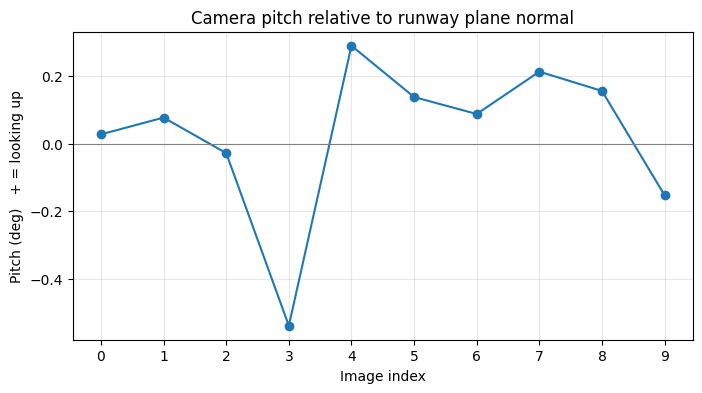

In [14]:
# Plot pitch angle vs image
plt.figure(figsize=(8, 4))
plt.plot(np.arange(gnav.im_num), pitch, 'o-')
plt.axhline(0, color='gray', lw=0.8)
plt.xticks(np.arange(gnav.im_num))
plt.xlabel('Image index')
plt.ylabel('Pitch (deg)   + = looking up')
plt.title('Camera pitch relative to runway plane normal')
plt.grid(alpha=0.3)
plt.show()

### Gradient overlay
Project ROI, place on satellite with ground truth (ind_params_KBCB), overlay image |grad| on satellite |grad|

In [15]:
# Per-image ROI (x, y, width, height) - lower image only, horizon is ~row 435
# Heights vary (867-874), so each ROI runs to the bottom of its own image
x0, y0 = 50, 550
rois = np.array([(x0, y0, gnav.images_dict[i].shape[1] - 2*x0, gnav.images_dict[i].shape[0] - y0)
                 for i in range(gnav.im_num)])
project_roi(gnav, rois)

# Place every image on the satellite with ground truth (scale, yaw [rad], x, y)
gnav.implement_guess_ind(ind_params_KBCB)

Image 0: 475500 pts, range min/max = 0.362/1.480, max/min = 4.1, r <= 0: 0
Image 1: 477000 pts, range min/max = 0.355/1.493, max/min = 4.2, r <= 0: 0
Image 2: 478500 pts, range min/max = 0.344/1.393, max/min = 4.1, r <= 0: 0
Image 3: 480000 pts, range min/max = 0.325/1.212, max/min = 3.7, r <= 0: 0
Image 4: 481500 pts, range min/max = 0.336/1.448, max/min = 4.3, r <= 0: 0
Image 5: 481500 pts, range min/max = 0.328/1.392, max/min = 4.2, r <= 0: 0
Image 6: 483000 pts, range min/max = 0.317/1.328, max/min = 4.2, r <= 0: 0
Image 7: 484500 pts, range min/max = 0.314/1.366, max/min = 4.3, r <= 0: 0
Image 8: 484500 pts, range min/max = 0.307/1.367, max/min = 4.5, r <= 0: 0
Image 9: 486000 pts, range min/max = 0.289/1.202, max/min = 4.2, r <= 0: 0


In [16]:
def grad_mag(gray):
    """
    Sobel gradient magnitude on a grayscale image (0-1)
    Output: |grad| per pixel, same shape as input
    """
    gx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
    return np.hypot(gx, gy)

# Camera: gradient on full image (no border effects at ROI edge), then crop to ROI
# Crop is row-major (h, w) - same order as im_mosaic pts
gray_cam = cv2.cvtColor(gnav.images_dict[im_ind], cv2.COLOR_BGR2GRAY).astype(np.float64) / 255
x, y, w, h = rois[im_ind]
g_im = grad_mag(gray_cam)[y:y+h, x:x+w].ravel()

# Satellite: gradient on full sat image - ravel matches ref_pts order
g_sat = grad_mag(gnav.sat_ref.astype(np.float64) / 255).ravel()

# Normalize each to ~0-1 by its own 99th percentile
g_im = np.minimum(g_im / np.percentile(g_im, 99), 1)
g_sat = np.minimum(g_sat / np.percentile(g_sat, 99), 1)

In [17]:
# Gradient overlay: projected image |grad| on top of satellite |grad|
vis = o3d.visualization.Visualizer()
vis.create_window(window_name=f"Gradient overlay (image {im_ind})")

# Image gradient - orange tint so it stands out from the gray satellite
im_cloud = o3d.geometry.PointCloud()
im_cloud.points = o3d.utility.Vector3dVector(gnav.im_pts_best_guess[im_ind]['pts'])
im_cloud.colors = o3d.utility.Vector3dVector(g_im[:, None] * np.array([1.0, 0.55, 0.1]))
vis.add_geometry(im_cloud)

# Satellite gradient - gray, ravel order matches ref_pts
ref_cloud = o3d.geometry.PointCloud()
ref_cloud.points = o3d.utility.Vector3dVector(gnav.ref_pts)
ref_cloud.colors = o3d.utility.Vector3dVector(np.repeat(g_sat[:, None], 3, axis=1))
vis.add_geometry(ref_cloud)

vis.run()
vis.destroy_window()

## Adjusting pitch

In [25]:
# Pitch perturbation (deg) about camera x-axis - + = optical axis tips up (COLMAP cam: y down, z forward)
d_pitch = -0.35

# Project ONLY im_ind (reuses ROI pts from gradient overlay cells) - same steps as project_roi
c, s = np.cos(np.deg2rad(d_pitch)), np.sin(np.deg2rad(d_pitch))
T_pitch = np.array([[1, 0, 0, 0],
                    [0, c, -s, 0],
                    [0, s, c, 0],
                    [0, 0, 0, 1]])
pts_vec_c, __ = gnav.unit_vec_c(im_ind)
__, homog_c2w_p = gnav.get_pose_id(gnav.im_ids[im_ind], im_ind)
homog_c2w_p = homog_c2w_p @ T_pitch
origin_c, __, pts_vec_w = gnav.unit_vec_tform(pts_vec_c, gnav.origin_w, homog_c2w_p)
__, pts_w = gnav.pt_range(pts_vec_w, homog_c2w_p, origin_c, im_ind)
__, pts_r, __ = gnav.unit_vec_tform(pts_w, gnav.origin_w, gnav.tform_ref_frame_pts)

# Same ground truth placement as nominal (implement_guess_ind, one image) - misalignment = pitch effect
scale, yaw, tx, ty = ind_params_KBCB[im_ind]
pts_r[:, :2] *= scale
__, pts_pitch, __ = gnav.unit_vec_tform(pts_r, gnav.origin_w, gnav.tform_create(tx, ty, 0, 0, 0, yaw))

plot_pts = [(gnav.im_pts_best_guess[im_ind]['pts'], g_im, [1.0, 0.55, 0.1]),
            (pts_pitch, g_im, [0.1, 0.8, 1.0]),
            (gnav.ref_pts, g_sat, [1.0, 1.0, 1.0])]

plot_pts_norm = [#(gnav.im_pts_best_guess[im_ind]['pts'], gnav.im_mosaic[im_ind]['color_g'], [1.0, 0.55, 0.1]),
            (pts_pitch, gnav.im_mosaic[im_ind]['color_g'], [0.1, 0.8, 1.0]),
            (gnav.ref_pts, gnav.ref_rgb, [1.0, 1.0, 1.0])]

# Overlay: nominal (orange) and perturbed (cyan) image |grad| on satellite |grad| (gray)
vis = o3d.visualization.Visualizer()
vis.create_window(window_name=f"Pitch {d_pitch:+.2f} deg (image {im_ind})")
for pts, g, col in plot_pts_norm:
    cloud = o3d.geometry.PointCloud()
    cloud.points = o3d.utility.Vector3dVector(pts)
    cloud.colors = o3d.utility.Vector3dVector(g * np.array(col))
    # cloud.colors = o3d.utility.Vector3dVector(g[:, None] * np.array(col))
    vis.add_geometry(cloud)
vis.run()
vis.destroy_window()

Initial: SSD at (0,0) = 0.06168, min = 0.05844 at shift (5, 2)
Pitch -0.35 deg: SSD at (0,0) = 0.05913, min = 0.05811 at shift (5, 5)


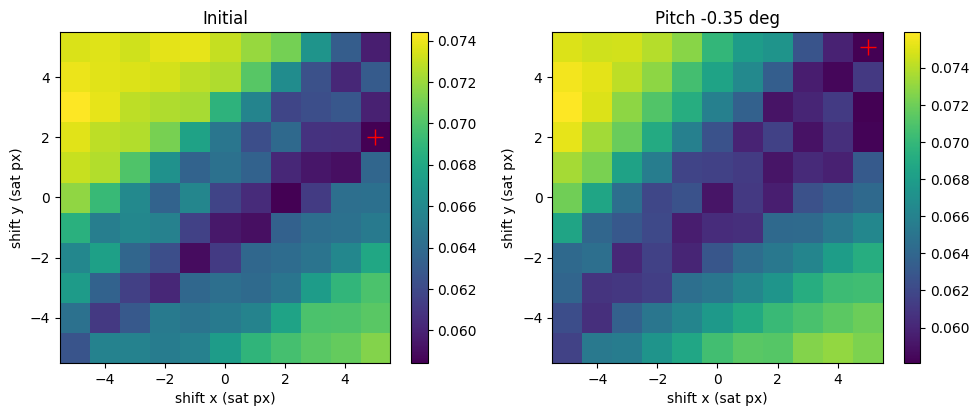

In [26]:
from matplotlib.path import Path

def ssd_grad(pts, n=5):
    """
    Gradient SSD of projected image pts vs satellite, over (2n+1)^2 shifts (sat px) - same idea as gnav.ssd_nxn
    Sat pts inside the image footprint (corner polygon) -> nearest image pt -> (g_sat - g_im)^2
    Uses MEAN (not sum) since pitch changes footprint size / number of sat pts
    Output: ssds[shiftx + n, shifty + n]
    """
    corners = gnav.im_pts_2d[im_ind]['corners']
    idxs = [0, -corners[2], -1, corners[2]-1]  # same corner indices as get_inside_sat_pts
    tree = cKDTree(pts[:, :2])  # build once - shift the sat pts by -shift instead of shifting image pts
    ssds = np.zeros((2*n+1, 2*n+1))
    for sx in range(-n, n+1):
        for sy in range(-n, n+1):
            sat_xy = gnav.ref_pts[:, :2] - np.array([sx, sy])
            mask = Path(pts[idxs, :2]).contains_points(sat_xy)
            __, idx = tree.query(sat_xy[mask], k=1)
            ssds[sx + n, sy + n] = np.mean((g_sat[mask] - g_im[idx])**2)
    return ssds

n = 5
ssd_nom = ssd_grad(gnav.im_pts_best_guess[im_ind]['pts'], n)
ssd_pit = ssd_grad(pts_pitch, n)

fig, axs = plt.subplots(1, 2, figsize=(10, 4))
for ax, ssds, name in zip(axs, [ssd_nom, ssd_pit], ['Initial', f'Pitch {d_pitch:+.2f} deg']):
    ix, iy = np.unravel_index(np.argmin(ssds), ssds.shape)
    print(f"{name}: SSD at (0,0) = {ssds[n, n]:.5f}, min = {ssds.min():.5f} at shift ({ix-n}, {iy-n})")
    im = ax.imshow(ssds.T, origin='lower', extent=[-n-0.5, n+0.5, -n-0.5, n+0.5])#, cmap='Blues')
    ax.plot(ix-n, iy-n, 'r+', ms=12)
    ax.set_title(name); ax.set_xlabel('shift x (sat px)'); ax.set_ylabel('shift y (sat px)')
    fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

Pitch +0.00 deg: SSD at (0,0) = 0.06168, min = 0.05844 at shift (5, 2)
Pitch +0.25 deg: SSD at (0,0) = 0.06178, min = 0.05805 at shift (5, 2)
Pitch -0.25 deg: SSD at (0,0) = 0.06077, min = 0.05870 at shift (5, 5)
Pitch -0.50 deg: SSD at (0,0) = 0.05969, min = 0.05731 at shift (5, 5)
Pitch -0.75 deg: SSD at (0,0) = 0.06077, min = 0.05697 at shift (0, 2)
Pitch -1.00 deg: SSD at (0,0) = 0.06774, min = 0.06001 at shift (-3, 0)


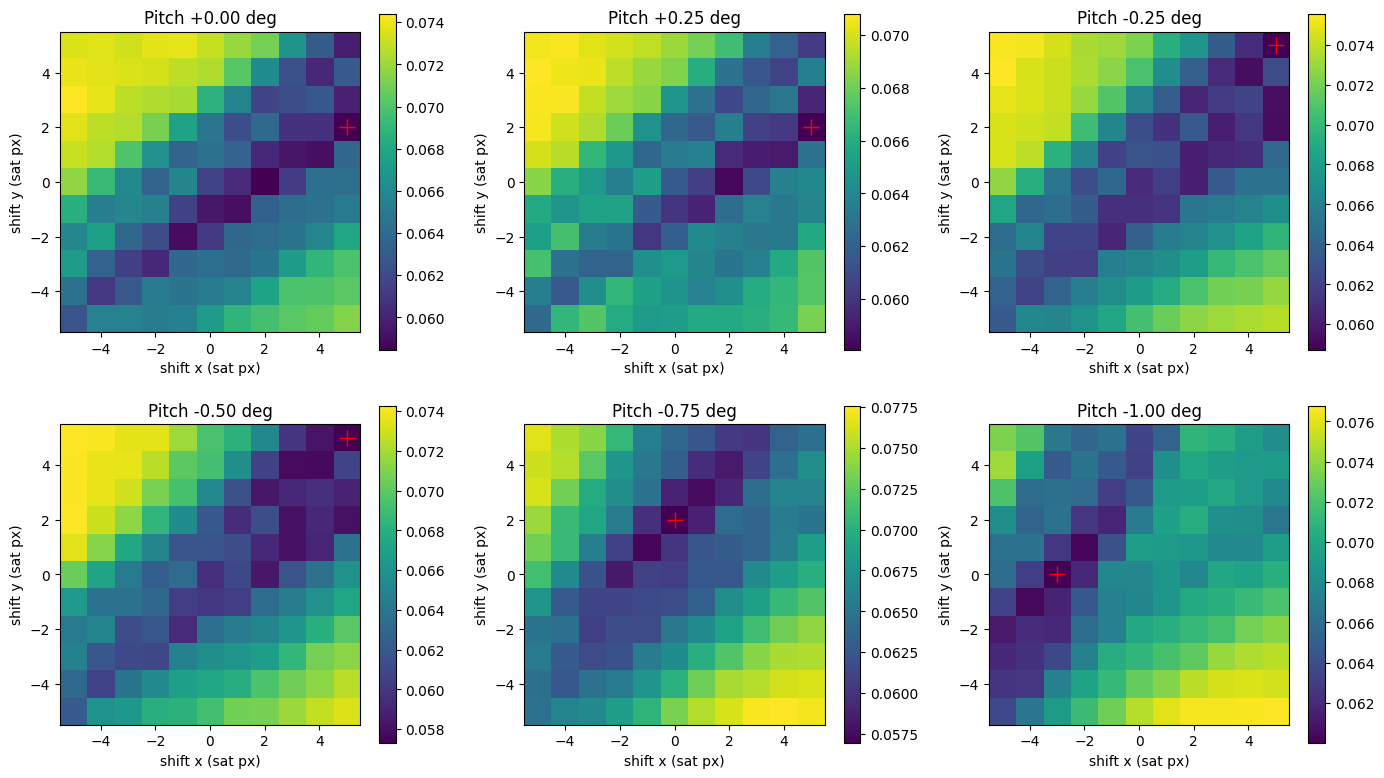

In [27]:
# Pitch sweep - gradient SSD for each pitch perturbation (im_ind only, same steps as the pitch cell above)
d_pitches = [0.0, 0.25, -0.25, -0.5, -0.75, -1.0]  # 0.0 = original
scale, yaw, tx, ty = ind_params_KBCB[im_ind]
pts_vec_c, __ = gnav.unit_vec_c(im_ind)
__, homog_c2w_0 = gnav.get_pose_id(gnav.im_ids[im_ind], im_ind)

fig, axs = plt.subplots(2, 3, figsize=(14, 8))
for ax, dp in zip(axs.ravel(), d_pitches):
    # Project with pitch perturbation, then same ground truth placement
    c, s = np.cos(np.deg2rad(dp)), np.sin(np.deg2rad(dp))
    T_pitch = np.array([[1, 0, 0, 0],
                        [0, c, -s, 0],
                        [0, s, c, 0],
                        [0, 0, 0, 1]])
    homog_c2w_p = homog_c2w_0 @ T_pitch
    origin_c, __, pts_vec_w = gnav.unit_vec_tform(pts_vec_c, gnav.origin_w, homog_c2w_p)
    __, pts_w = gnav.pt_range(pts_vec_w, homog_c2w_p, origin_c, im_ind)
    __, pts_r, __ = gnav.unit_vec_tform(pts_w, gnav.origin_w, gnav.tform_ref_frame_pts)
    pts_r[:, :2] *= scale
    __, pts_dp, __ = gnav.unit_vec_tform(pts_r, gnav.origin_w, gnav.tform_create(tx, ty, 0, 0, 0, yaw))

    # SSD grid
    ssds = ssd_grad(pts_dp, n)
    ix, iy = np.unravel_index(np.argmin(ssds), ssds.shape)
    print(f"Pitch {dp:+.2f} deg: SSD at (0,0) = {ssds[n, n]:.5f}, min = {ssds.min():.5f} at shift ({ix-n}, {iy-n})")

    im = ax.imshow(ssds.T, origin='lower', extent=[-n-0.5, n+0.5, -n-0.5, n+0.5])
    ax.plot(ix-n, iy-n, 'r+', ms=12)
    ax.set_title(f'Pitch {dp:+.2f} deg'); ax.set_xlabel('shift x (sat px)'); ax.set_ylabel('shift y (sat px)')
    fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

## Intrinsic deep dive

Checking effect of focal length differences

f = 1626.0: SSD at (0,0) = 0.06168, min = 0.05844 at shift (5, 2)
f = 1243.1: SSD at (0,0) = 0.06155, min = 0.05764 at shift (3, 3)


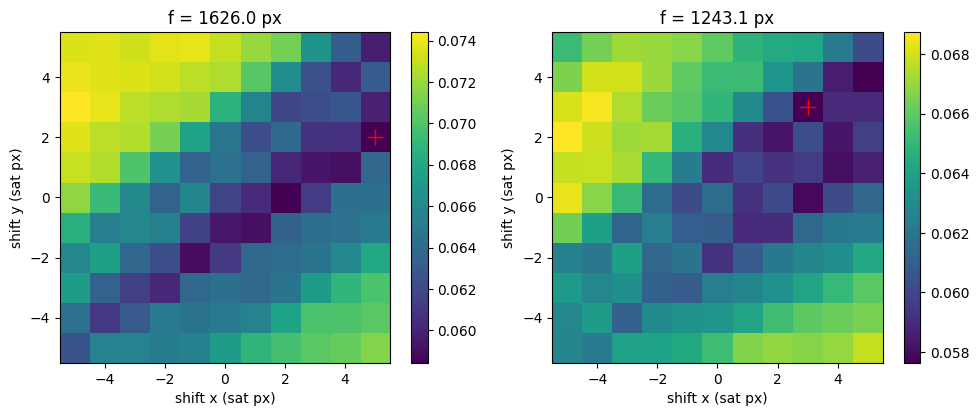

In [ ]:
# Focal comparison (image im_ind): code focal vs dense/1 PINHOLE focal, same pose + GT placement
f_code = gnav.focal   # 1626 - cam[78], 2448-px scale, used for all images
f_dense = 1243.13     # HARDCODED: dense/1/sparse fx for frame_26549 (im_ind = 4)
scale, yaw, tx, ty = ind_params_KBCB[im_ind]
__, homog_c2w_0 = gnav.get_pose_id(gnav.im_ids[im_ind], im_ind)

# f_code last so stored side effects (im_pts_2d mag / r) end at the nominal focal
pts_f = {}
pts_r_f = {}
for f in [f_dense, f_code]:
    gnav.focal = f
    pts_vec_c, __ = gnav.unit_vec_c(im_ind)
    origin_c, __, pts_vec_w = gnav.unit_vec_tform(pts_vec_c, gnav.origin_w, homog_c2w_0)
    __, pts_w = gnav.pt_range(pts_vec_w, homog_c2w_0, origin_c, im_ind)
    __, pts_r, __ = gnav.unit_vec_tform(pts_w, gnav.origin_w, gnav.tform_ref_frame_pts)
    pts_r_f[f] = pts_r.copy()  # unscaled ref-frame pts - for manual alignment cell
    pts_r[:, :2] *= scale
    __, pts_f[f], __ = gnav.unit_vec_tform(pts_r, gnav.origin_w, gnav.tform_create(tx, ty, 0, 0, 0, yaw))
gnav.focal = f_code  # restore

# # Gradient SSD for each focal
# fig, axs = plt.subplots(1, 2, figsize=(10, 4))
# for ax, f in zip(axs, [f_code, f_dense]):
#     ssds = ssd_grad(pts_f[f], n)
#     ix, iy = np.unravel_index(np.argmin(ssds), ssds.shape)
#     print(f"f = {f:.1f}: SSD at (0,0) = {ssds[n, n]:.5f}, min = {ssds.min():.5f} at shift ({ix-n}, {iy-n})")
#     im = ax.imshow(ssds.T, origin='lower', extent=[-n-0.5, n+0.5, -n-0.5, n+0.5])
#     ax.plot(ix-n, iy-n, 'r+', ms=12)
#     ax.set_title(f'f = {f:.1f} px'); ax.set_xlabel('shift x (sat px)'); ax.set_ylabel('shift y (sat px)')
#     fig.colorbar(im, ax=ax)
# plt.tight_layout()
# plt.show()


In [58]:
# Manual alignment for f_dense - edit params and re-run, then view in the overlay cell below
scale_d, yaw_d, tx_d, ty_d = ind_params_KBCB[im_ind]  # start from GT (fit with f_code) - yaw in rad
# scale_d = 130
tx_d, ty_d = 358, 308


pts_r = pts_r_f[f_dense].copy()
pts_r[:, :2] *= scale_d
__, pts_f[f_dense], __ = gnav.unit_vec_tform(pts_r, gnav.origin_w, gnav.tform_create(tx_d, ty_d, 0, 0, 0, yaw_d))

ssds = ssd_grad(pts_f[f_dense], n)
ix, iy = np.unravel_index(np.argmin(ssds), ssds.shape)
print(f"f = {f_dense:.1f}, scale = {scale_d}, yaw = {yaw_d:.4f} rad, x/y = {tx_d}/{ty_d}: "
      f"SSD at (0,0) = {ssds[n, n]:.5f}, min = {ssds.min():.5f} at shift ({ix-n}, {iy-n})")

f = 1243.1, scale = 130.0, yaw = 5.9690 rad, x/y = 358/308: SSD at (0,0) = 0.05803, min = 0.05259 at shift (4, 4)


In [66]:
# Overlay: f_code (orange) and f_dense (cyan) image |grad| on satellite |grad| (gray)
vis = o3d.visualization.Visualizer()
vis.create_window(window_name=f"Focal {f_code:.0f} vs {f_dense:.0f} px (image {im_ind})")


plot_pts_foc = [(pts_f[f_code], g_im, [1.0, 0.55, 0.1]),
                    (pts_f[f_dense], g_im, [0.1, 0.8, 1.0]),
                    (gnav.ref_pts, g_sat, [1.0, 1.0, 1.0])]

plot_pts_foc_norm = [(pts_f[f_code], gnav.im_mosaic[im_ind]['color_g'], [1.0, 0.55, 0.1]),
            (pts_f[f_dense], gnav.im_mosaic[im_ind]['color_g'], [0.1, 0.8, 1.0]),
            (gnav.ref_pts, gnav.ref_rgb, [1.0, 1.0, 1.0])]

for pts, g, col in plot_pts_foc_norm:
    cloud = o3d.geometry.PointCloud()
    cloud.points = o3d.utility.Vector3dVector(pts)
    # cloud.colors = o3d.utility.Vector3dVector(g[:, None] * np.array(col))
    cloud.colors = o3d.utility.Vector3dVector(g * np.array(col))
    vis.add_geometry(cloud)

axis_origin = o3d.geometry.TriangleMesh.create_coordinate_frame(size=10)
vis.add_geometry(axis_origin)
vis.run()
vis.destroy_window()


f = 1626.0 px (GT): SSD at (0,0) = 0.06168, min = 0.05844 at shift (5, 2)
f = 1243.1 px : SSD at (0,0) = 0.05803, min = 0.05259 at shift (4, 4)


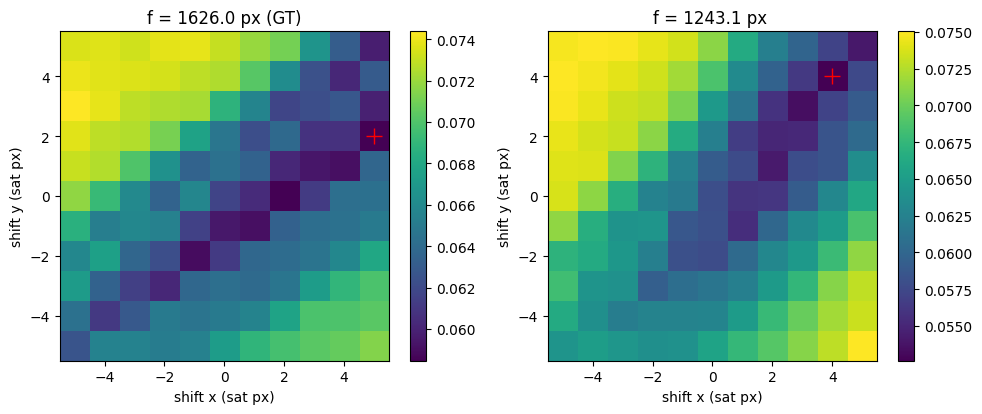

In [62]:
# Gradient SSD: f_code at GT placement vs f_dense at manual placement (from cell above)
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
for ax, f, name in zip(axs, [f_code, f_dense],
                       [f'f = {f_code:.1f} px (GT)', f'f = {f_dense:.1f} px ']): #(x/y = {tx_d}/{ty_d}, scale = {scale_d})']):
    ssds = ssd_grad(pts_f[f], n)
    ix, iy = np.unravel_index(np.argmin(ssds), ssds.shape)
    print(f"{name}: SSD at (0,0) = {ssds[n, n]:.5f}, min = {ssds.min():.5f} at shift ({ix-n}, {iy-n})")
    im = ax.imshow(ssds.T, origin='lower', extent=[-n-0.5, n+0.5, -n-0.5, n+0.5])
    ax.plot(ix-n, iy-n, 'r+', ms=12)
    ax.set_title(name); ax.set_xlabel('shift x (sat px)'); ax.set_ylabel('shift y (sat px)')
    fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

Number of points used for image 4:  (12413,)
f = 1626.0 px (GT): SSD at (0,0) = 63.75, min = 63.73 at shift (3, 2)
Number of points used for image 4:  (9137,)
f = 1243.1 px: SSD at (0,0) = 43.91, min = 43.91 at shift (0, 0)


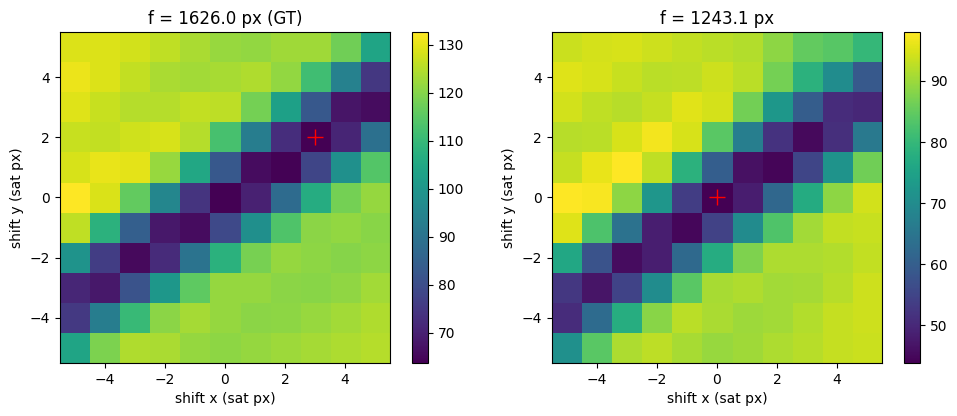

In [64]:
# Normal (intensity) SSD - gnav.ssd_nxn on f_code (GT) vs f_dense (manual placement)
# ssd_nxn reads gnav.im_pts_best_guess[im_ind]['pts'] -> swap in each projection, then restore
pts_best_0 = gnav.im_pts_best_guess[im_ind]['pts']
ssd_int = {}  # kept for plotly cell
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
for ax, f, name in zip(axs, [f_code, f_dense], [f'f = {f_code:.1f} px (GT)', f'f = {f_dense:.1f} px']):
    gnav.im_pts_best_guess[im_ind]['pts'] = pts_f[f]
    ssds = ssd_int[f] = gnav.ssd_nxn(n, im_ind)
    ix, iy = np.unravel_index(np.argmin(ssds), ssds.shape)
    print(f"{name}: SSD at (0,0) = {ssds[n, n]:.2f}, min = {ssds.min():.2f} at shift ({ix-n}, {iy-n})")
    im = ax.imshow(ssds.T, origin='lower', extent=[-n-0.5, n+0.5, -n-0.5, n+0.5])
    ax.plot(ix-n, iy-n, 'r+', ms=12)
    ax.set_title(name); ax.set_xlabel('shift x (sat px)'); ax.set_ylabel('shift y (sat px)')
    fig.colorbar(im, ax=ax)
gnav.im_pts_best_guess[im_ind]['pts'] = pts_best_0  # restore
plt.tight_layout()
plt.show()

In [65]:
import plotly.graph_objects as go

# SSD surface plots (plotly) - intensity SSD for each focal (same style as lsa_example)
x = np.linspace(-n, n, 2*n + 1)
Y, X = np.meshgrid(x, x)  # ssds indexed [shiftx + n, shifty + n]

for f, ssds in ssd_int.items():
    idrow, idcol = np.unravel_index(np.argmin(ssds), ssds.shape)
    fig = go.Figure()
    fig.add_surface(x=X, y=Y, z=ssds, colorscale='Viridis', colorbar=dict(title='SSD'), name='SSD Surface')
    fig.add_trace(go.Scatter3d(x=[idrow - n], y=[idcol - n], z=[ssds[idrow, idcol]],
                               mode='markers', marker=dict(size=6, color='red'), name='Min SSD'))
    fig.add_trace(go.Scatter3d(x=[0], y=[0], z=[ssds[n, n]],
                               mode='markers', marker=dict(size=6, color='black'), name='Placement (0,0)'))
    fig.update_layout(
        title=f'Intensity SSD: image {im_ind}, f = {f:.1f} px',
        scene=dict(xaxis=dict(title='X Shift (pixels)', range=[-n, n], dtick=1),
                   yaxis=dict(title='Y Shift (pixels)', range=[-n, n], dtick=1),
                   zaxis=dict(title='SSD'),
                   camera=dict(eye=dict(x=1.5, y=1.5, z=1.2)),
                   aspectmode='cube'),
        width=900, height=800)
    fig.show()